<a href="https://colab.research.google.com/github/aneal191/Data-201-Project1/blob/main/Project_1_Andrew_Neal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 1

In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/bank-full.csv', sep=';')

# Examine the first five records
print(df.head())

# Check dimensions
print("Shape:", df.shape)

# Check missing values
print(df.isnull().sum())

# Examine the target variable
print(df['y'].value_counts(normalize=True))

   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married    unknown      no     1506     yes   no   
4   33       unknown   single    unknown      no        1      no   no   

   contact  day month  duration  campaign  pdays  previous poutcome   y  
0  unknown    5   may       261         1     -1         0  unknown  no  
1  unknown    5   may       151         1     -1         0  unknown  no  
2  unknown    5   may        76         1     -1         0  unknown  no  
3  unknown    5   may        92         1     -1         0  unknown  no  
4  unknown    5   may       198         1     -1         0  unknown  no  
Shape: (45211, 17)
age          0
job          0
marital      0
education    0
default      0
balance      0
ho

## Part 1: Understand Your Problem

### Question 1: What does each row represent?
Each row represents one bank marketing contact record, including customer information, campaign information, and whether the customer subscribed to a term deposit.
The response variable is y, with two possible classes:
- yes — the customer subscribed.
- no — the customer did not subscribe.

### Question 2: Which predictors should we use?
The bank dataset has 16 potential predictors. Some examples are:

age, occupation, marital status, education level, average yearly account balance, whether the customer has a housing loan, whether the customer has a personal loan, number of contacts during the current campaign, previous campaign contacts, outcome of previous campaign

We will exclude duration of the  phone call.

### Question 3: Examine the distribution of your response variable.

- How many observations belong to each class?


In [ ]:
df['y'].value_counts()


,count
y,
no,39922
yes,5289


- Is the dataset reasonably balanced or imbalanced?

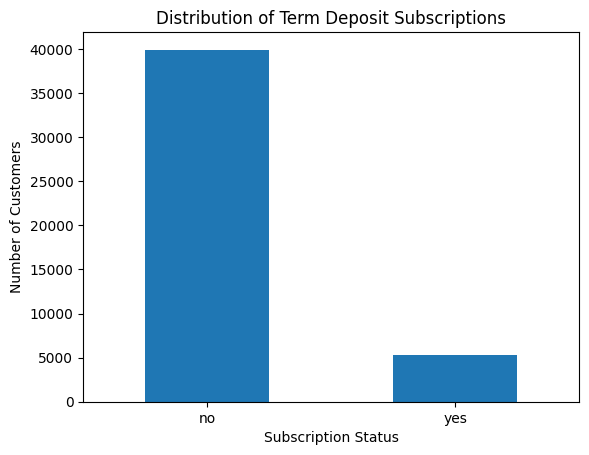

In [ ]:
df['y'].value_counts(normalize=True) * 100

import matplotlib.pyplot as plt

df['y'].value_counts().plot(kind='bar')

plt.title('Distribution of Term Deposit Subscriptions')
plt.xlabel('Subscription Status')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()


The dataset is imbalanced, because substantially more customers belong to the "no" class than the "yes" class.

### Question 4: Define a false positive and false negative in the context of your dataset.

- False Positive (FP): The model predicts that a customer will subscribe to a term deposit, but the customer actually does not subscribe. This could cause the bank to waste time and money contacting customers who aren't interested.

- False Negative (FN): The model predicts that a customer will not subscribe to a term deposit, but the customer actually does subscribe. This could cause the bank to miss potential customers and lose revenue.

### Question 5: Which type of error would you be more concerned about in this application, or are they *similarly* important? Explain your reasoning.

I would be more concerned about false negatives because they represent missed opportunities to acquire customers who would have subscribed to a term deposit. While false positives result in wasted marketing expenses, false negatives could result in lost revenue and potential long-term customer relationships.

However, the relative importance of these errors depends on the cost of contacting customers compared to the potential revenue generated by a successful subscription.

## Part 2: Explore and Prepare the Data

### Question 1: Investigate your features and predictors.


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [ ]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [ ]:
df.describe(include='object')

,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211
unique,12,3,4,2,2,2,3,12,4,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,36959,39922


### Question 2: Determine whether your dataset contains missing values. If it does, explain how you handled them.

In [ ]:
(df == 'unknown').sum()

,0
age,0
job,288
marital,0
education,1857
default,0
balance,0
housing,0
loan,0
contact,13020
day,0


None of the 17 columns contained null values. But I found that several categorical predictors contained "unknown" values, including job, education, contact, and poutcome. I decided to retain "unknown" as a separate category rather than remove these observations, since removing them could result in significant data loss.

### Question 3: Determine whether any categorical predictors need to be encoded before modeling.

In [ ]:
# Identify categorical variables
df.select_dtypes(include=['object']).columns

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'y'],
      dtype='object')

In [ ]:
# Separate the predictors from the response variable
# Exclude duration because call length is unknown before contacting a customer
X = df.drop(columns=['y', 'duration'])

# Convert response variable to binary values
y = df['y'].map({'no': 0, 'yes': 1})

# Identify categorical predictors
categorical_cols = X.select_dtypes(
    include=['object']
).columns.tolist()

print(categorical_cols)

['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


The dataset contains nine categorical predictors: job, marital, education, default, housing, loan, contact, month, and poutcome.

Because the classification models require numerical inputs, these categorical predictors will need to be one-hot encoded to convert each category into binary variables.

I will also convert the response variable, y, into binary values, where 0 represents customers who did not subscribe and 1 represents customers who subscribed.

### Question 4: Divide the data, then use k-fold CV on training data.

In [ ]:
from sklearn.model_selection import train_test_split

# Split into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 36168
Testing observations: 9043


In [ ]:
from sklearn.model_selection import StratifiedKFold

# Create 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Number of folds:", cv.get_n_splits())

Number of folds: 5


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

# Identify numerical and categorical predictors
numeric_cols = X_train.select_dtypes(
    include='number'
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include='object'
).columns.tolist()

# Prepare predictors
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore',
        drop='first'
    ), categorical_cols)
])

# Create a preliminary logistic regression pipeline
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000))
])

# Perform 5-fold cross-validation
cv_scores = cross_val_score(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc'
)

print("ROC-AUC for each fold:", cv_scores)
print("Mean ROC-AUC:", cv_scores.mean())


ROC-AUC for each fold: [0.76139418 0.76459204 0.75838096 0.76764657 0.76221795]
Mean ROC-AUC: 0.7628463414875877


I divided the dataset into 80% training data (36,168 observations) and 20% testing data (9,043 observations). I used stratified sampling to preserve the proportions of subscribers and nonsubscribers in both datasets.

I then used 5-fold stratified cross-validation on the training data. This divides the training data into five subsets, repeatedly using four subsets for training and one for validation.

I used ROC-AUC to evaluate a preliminary Logistic Regression model because the response variable is imbalanced. Cross-validation helps estimate how well the model generalizes to unseen data.

I kept the testing dataset separate so it can be used for the final comparison of the four classifiers.

### Question 5: Determine whether predictors should be standardized for any of the classifiers you will use.

I will standardize the numerical predictors because they have different scales. This is especially important for KNN, which uses distances to classify observations. Standardization also helps Logistic Regression converge, while LDA and QDA generally do not require it. I used StandardScaler within a pipeline to prevent data leakage.

## Part 3: Build Your Classifiers


In [ ]:
# Logistic Regression

# Predict probability of subscribing
log_prob = log_model.predict_proba(X_test)[:, 1]

# Display actual results, predictions, and probabilities
log_results = pd.DataFrame({
    'Actual': pd.Series(y_test).to_numpy(),
    'Predicted': log_pred,
    'Probability of Yes': log_prob
})

display(log_results.head(10))


,Actual,Predicted,Probability of Yes
0,0,0,0.013251
1,0,0,0.025536
2,0,0,0.035771
3,0,0,0.017291
4,0,0,0.131292
5,0,0,0.048348
6,0,0,0.071002
7,1,1,0.838712
8,0,0,0.111147
9,0,0,0.095411


In [ ]:
# Linear Discriminant Analysis (LDA)

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
import pandas as pd

# Build the LDA model
lda_model = Pipeline([
    ('preprocessor', preprocessor),
    ('to_dense', FunctionTransformer(
        lambda x: x.toarray() if hasattr(x, 'toarray') else x,
        accept_sparse=True
    )),
    ('classifier', LinearDiscriminantAnalysis())
])

# Train the model
lda_model.fit(X_train, y_train)

# Predict outcomes for the test data
lda_pred = lda_model.predict(X_test)

# Display actual and predicted results
lda_results = pd.DataFrame({
    'Actual': pd.Series(y_test).to_numpy(),
    'Predicted': lda_pred
})

display(lda_results.head(10))


,Actual,Predicted
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
5,0,0
6,0,0
7,1,1
8,0,0
9,0,0


In [ ]:
# Quadratic Discriminant Analysis (QDA)

from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
import pandas as pd

# Build the QDA model
qda_model = Pipeline([
    ('preprocessor', preprocessor),
    ('to_dense', FunctionTransformer(
        lambda x: x.toarray() if hasattr(x, 'toarray') else x,
        accept_sparse=True
    )),
    ('classifier', QuadraticDiscriminantAnalysis(reg_param=0.1))
])

# Train the model
qda_model.fit(X_train, y_train)

# Predict outcomes for the test data
qda_pred = qda_model.predict(X_test)

# Display actual and predicted results
qda_results = pd.DataFrame({
    'Actual': pd.Series(y_test).to_numpy(),
    'Predicted': qda_pred
})

display(qda_results.head(10))


,Actual,Predicted
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
5,0,0
6,0,0
7,1,1
8,0,0
9,0,0


In [ ]:
# K-Nearest Neighbors (KNN)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
import pandas as pd

# Values of K to test
k_values = [3, 7, 15, 31]

# Set up 3-fold cross-validation
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

cv_scores = []

# Test each value of K
for k in k_values:
    knn_model = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', KNeighborsClassifier(n_neighbors=k))
    ])

    scores = cross_val_score(
        knn_model, X_train, y_train,
        cv=cv, scoring='roc_auc'
    )

    cv_scores.append(scores.mean())
    print(f"K = {k}, Mean ROC-AUC = {scores.mean():.4f}")

# Display results
knn_results = pd.DataFrame({
    'K': k_values,
    'Mean ROC-AUC': cv_scores
})

display(knn_results)


K = 3, Mean ROC-AUC = 0.6684
K = 7, Mean ROC-AUC = 0.7060
K = 15, Mean ROC-AUC = 0.7301
K = 31, Mean ROC-AUC = 0.7461


,K,Mean ROC-AUC
0,3,0.668362
1,7,0.706020
2,15,0.730099
3,31,0.746118


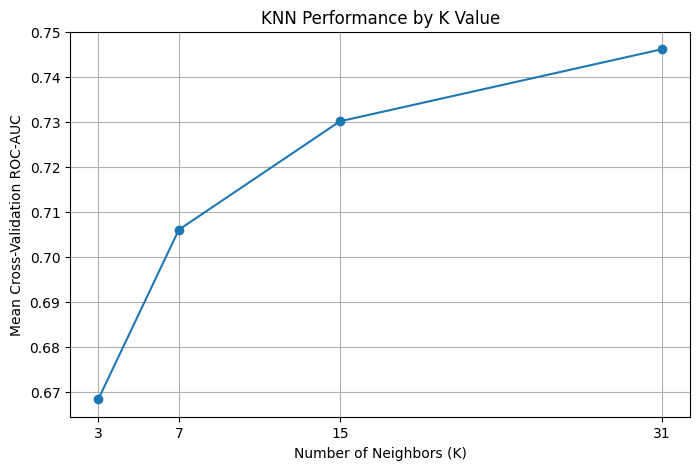

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(k_values, cv_scores, marker='o')

plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Mean Cross-Validation ROC-AUC')
plt.title('KNN Performance by K Value')
plt.xticks(k_values)
plt.grid(True)

plt.show()


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
import pandas as pd

# Select the best K from cross-validation
best_k = k_values[cv_scores.index(max(cv_scores))]

# Build the final KNN model
knn_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=best_k))
])

# Train the model
knn_model.fit(X_train, y_train)

# Generate test predictions
knn_pred = knn_model.predict(X_test)

# Generate predicted probabilities
knn_prob = knn_model.predict_proba(X_test)[:, 1]

# Display the results
knn_predictions = pd.DataFrame({
    'Actual': pd.Series(y_test).to_numpy(),
    'Predicted': knn_pred,
    'Probability of Yes': knn_prob
})

print("Selected K:", best_k)
display(knn_predictions.head(10))

Selected K: 31


,Actual,Predicted,Probability of Yes
0,0,0,0.000000
1,0,0,0.032258
2,0,0,0.064516
3,0,0,0.064516
4,0,0,0.096774
5,0,0,0.096774
6,0,0,0.032258
7,1,1,0.580645
8,0,0,0.161290
9,0,0,0.096774


I selected K = 31 because it produced the highest mean cross-validation ROC-AUC (0.7461) among the four K values tested. I trained the final KNN classifier using K = 31 and generated predictions for the test dataset.

## Part 4: Evaluate Your Models


### Question 1: Produce a confusion matrix for each model. Choose a threshold and explain why you chose it.

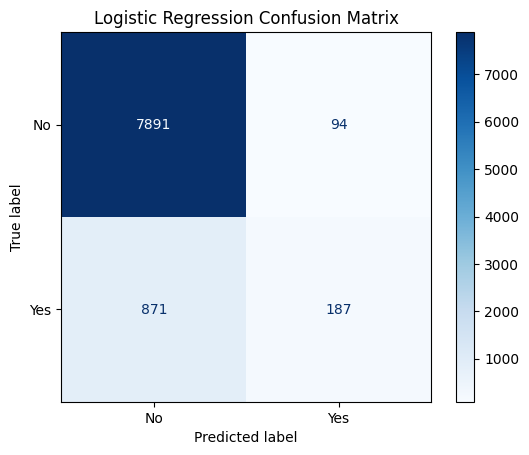

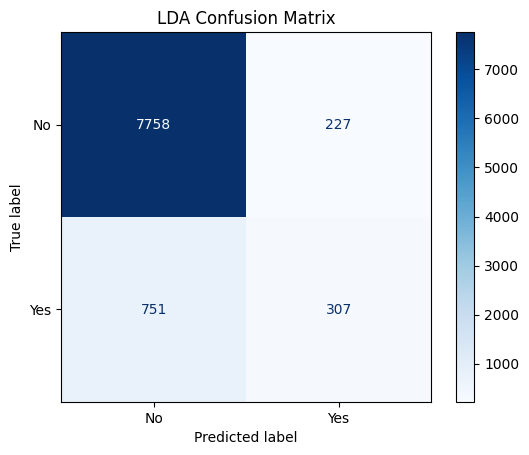

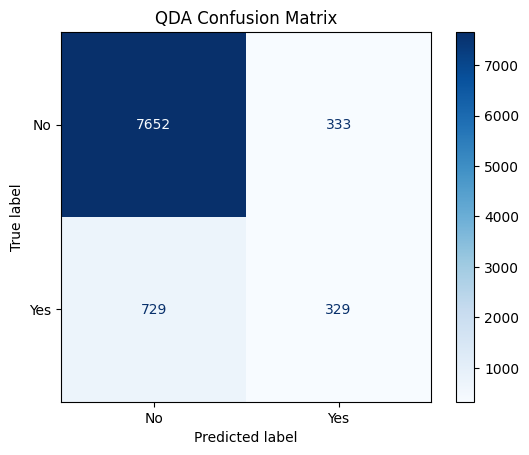

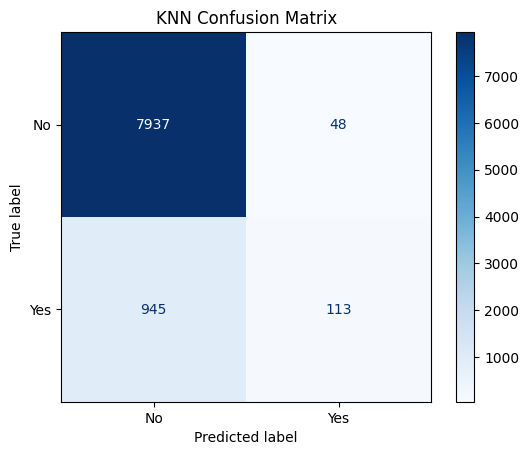

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

models = {
    'Logistic Regression': log_pred,
    'LDA': lda_pred,
    'QDA': qda_pred,
    'KNN': knn_pred
}

for name, predictions in models.items():
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['No', 'Yes']
    )

    disp.plot(cmap='Blues')
    plt.title(f'{name} Confusion Matrix')
    plt.show()


I created confusion matrices for all four classification models to compare their predictions with actual customer outcomes. I used the standard classification threshold of 0.50, meaning a customer is classified as likely to subscribe when the predicted probability is at least 50%. The confusion matrices show correct predictions as well as false positives and false negatives.

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)
import pandas as pd

# Four trained classifiers
models = {
    'Logistic Regression': log_model,
    'LDA': lda_model,
    'QDA': qda_model,
    'KNN': knn_model
}

results = []

for name, model in models.items():
    # Predictions and probabilities
    y_pred = model.predict(X_test)
    yes_index = list(model.classes_).index(1)
    y_prob = model.predict_proba(X_test)[:, yes_index]

    # Confusion matrix values
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    # Calculate performance metrics
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'Specificity': tn / (tn + fp),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

# Create comparison table
comparison = pd.DataFrame(results)

display(comparison.round(4))


,Model,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC
0,Logistic Regression,0.8933,0.6655,0.1767,0.9882,0.2793,0.7717
1,LDA,0.8919,0.5749,0.2902,0.9716,0.3857,0.7673
2,QDA,0.8826,0.4970,0.3110,0.9583,0.3826,0.7692
3,KNN,0.8902,0.7019,0.1068,0.9940,0.1854,0.7581


I evaluated Logistic Regression, LDA, QDA, and KNN using six performance metrics: accuracy, precision, recall, specificity, F1 score, and ROC-AUC.

## Part 5: Reflect

The four classification models produced different results. Logistic Regression had the highest accuracy at 89.33%, while KNN had the highest precision at 70.19%. QDA had the highest recall at 31.10%, meaning it identified the largest proportion of actual subscribers. LDA had the highest F1 score at 38.57%.

For this application, precision and recall are particularly important. Precision helps the bank avoid wasting money contacting customers who are unlikely to subscribe. Recall helps the bank identify more potential subscribers and avoid missing business opportunities.

Because the dataset is imbalanced, accuracy alone can be misleading. LDA appears to offer the best balance between precision and recall based on its F1 score, although the final choice should also consider ROC-AUC and the costs of classification errors.

## Part 6: ROC and AUC

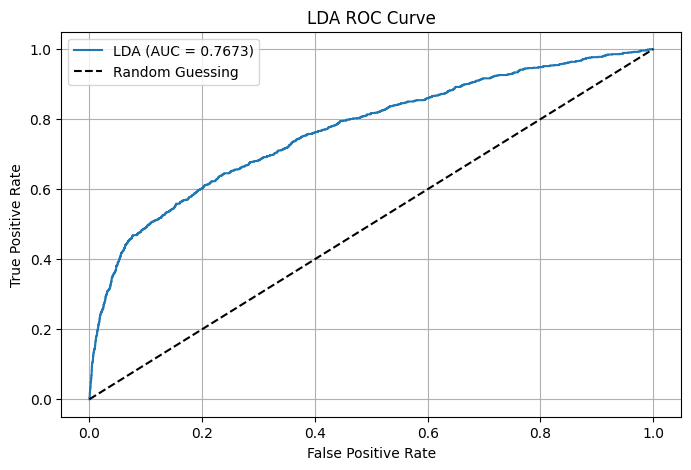

LDA ROC-AUC: 0.7673


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get LDA predicted probabilities
lda_prob = lda_model.predict_proba(X_test)[:, 1]

# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, lda_prob)
lda_auc = roc_auc_score(y_test, lda_prob)

# Plot ROC curve
plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f'LDA (AUC = {lda_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('LDA ROC Curve')
plt.legend()
plt.grid(True)
plt.show()

print(f'LDA ROC-AUC: {lda_auc:.4f}')

I created an ROC curve for the LDA model and obtained an ROC-AUC of 0.7673.

This means the model can distinguish between customers who subscribe and those who do not reasonably well. The ROC curve is above the diagonal line representing random guessing.

An ROC-AUC of 0.7673 indicates that the model performs better than random guessing, although there is still room for improvement.

## Part 7: Final Analysis

### Question 1: Compare the performance of your four classifiers. What are the most important differences?

All four models had similar accuracy, ranging from 88.26% to 89.33%. Logistic Regression had the highest accuracy, while KNN had the highest precision. QDA had the highest recall, meaning it identified the most actual subscribers.

LDA had the highest F1 score, suggesting it provided the best balance between precision and recall. The biggest difference between the models was their ability to identify subscribers rather than simply predict non-subscribers correctly.

### Question 2: Identify the model you would deploy for this specific application and justify the choice using your results and the consequences of classification errors.


I would choose LDA because it had the highest F1 score (38.57%), providing the best balance between precision and recall.

LDA identified 307 actual subscribers while producing 227 false positives. Although QDA identified slightly more subscribers, it also produced more false positives.

I believe LDA offers a reasonable balance between identifying potential customers and minimizing unnecessary marketing costs. However, the final decision would depend on the bank's actual marketing costs and the value of gaining a new customer.

### Question 3: Explain one limitation of your analysis.

One limitation of this analysis is that the dataset is imbalanced, with significantly more non-subscribers than subscribers. This can cause models to favor predicting that customers will not subscribe. As a result, the models may achieve high accuracy while missing many potential subscribers.

### Question 3: What additional information or data would you want before using this model in the real world?

Before using this model in the real world, I would want information about the cost of contacting each customer and the revenue generated from successful subscriptions. This would help determine whether the benefits of identifying potential subscribers outweigh the costs of contacting uninterested customers. I would also want more recent customer data to ensure the model remains accurate.

## Part 8: Presentation: The Model Pitch

See attached PDF.